Skills used: ['sql', 'python', 'excel', 'aws', 'azure', 'r', 'java', 'spark', 'gcp', 'kubernetes']
train rows: 510 | test rows: 120
share of 'up' months in the test set: 45.0 %
                         model  accuracy %  F1 score  MAE (on probability)  MAE (on 0/1 guess)
  always guess the most common        45.0      0.62                 0.502               0.550
logistic regression (baseline)        49.2      0.50                 0.509               0.508
       random forest (primary)        48.3      0.49                 0.501               0.517
logistic regression (baseline) confusion matrix [rows = actual 0/1, columns = predicted 0/1]:
[[28 38]
 [23 31]]
random forest (primary) confusion matrix [rows = actual 0/1, columns = predicted 0/1]:
[[28 38]
 [24 30]]
               window  always guess  logistic regression  random forest
Feb 2023 to\nJul 2023          50.0                 46.7           63.3
Aug 2023 to\nJan 2024          50.0                 50.0           65.0
Feb 2024

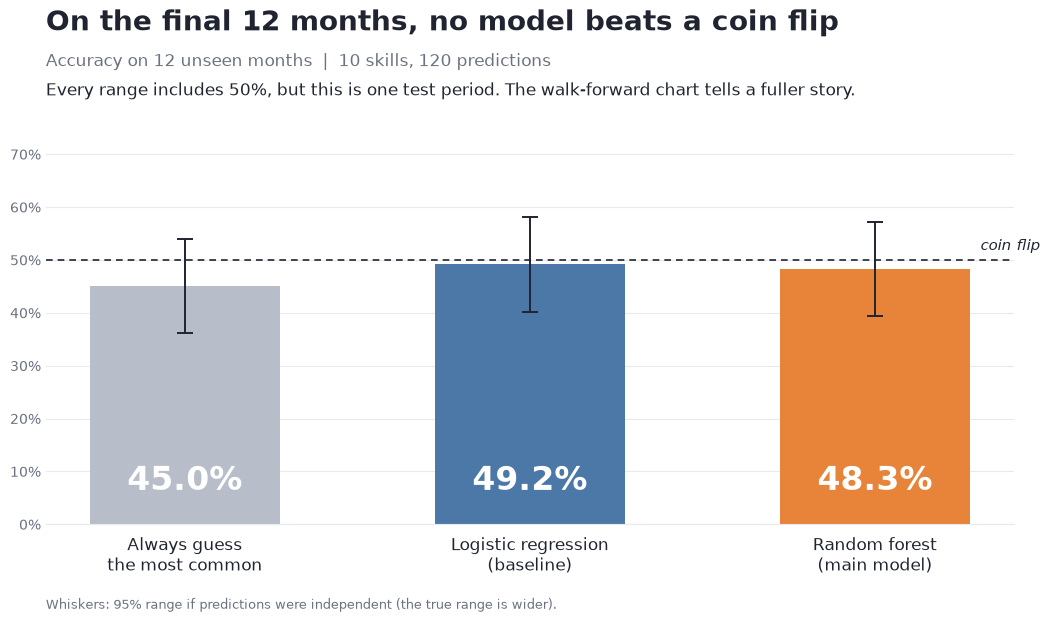

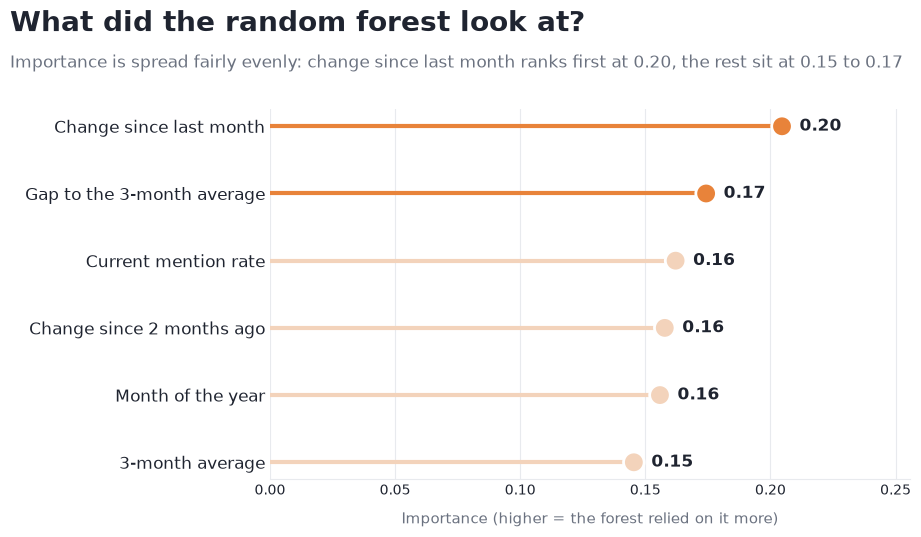

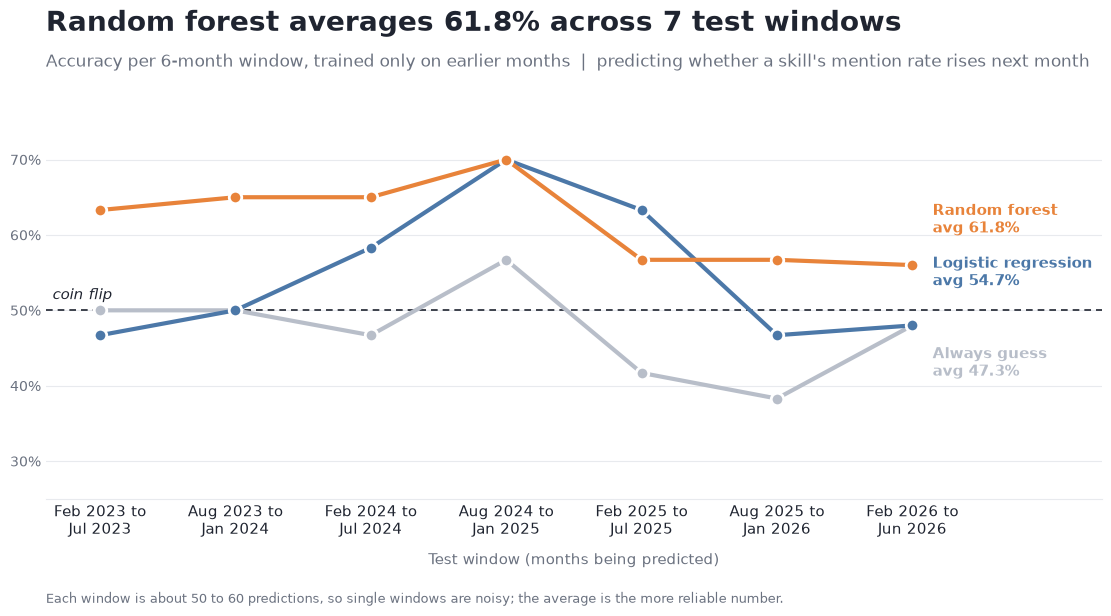

In [1]:
import numpy as np
import pandas as pd
import re
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix, mean_absolute_error

# load the dataset and standardize date columns.
jobs = pd.read_csv("Combined_Datasets_EDA 1.xls", dtype=str)
jobs["date"] = pd.to_datetime(jobs["Posting_date"], errors="coerce")

# only use Jan 2021 to Jun 2026 (the data after June 2026 gets unreliable so I left it out)
jobs = jobs[(jobs["date"] >= "2021-01-01") & (jobs["date"] < "2026-07-01")]
jobs["month"] = jobs["date"].dt.to_period("M").dt.to_timestamp()

# standardize skill names
def tidy_skill(s):
    s = str(s).lower()
    s = re.sub(r"[-_]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

#skills cleaning
def split_skills(text):
    text = str(text)
    if "'" in text:
        found = re.findall(r"'([^']*)'", text)
    else:
        found = text.strip("[]").split(",")
    out = [tidy_skill(x) for x in found if x.strip() != ""]
    return list(dict.fromkeys(out))  

split_map = {s: split_skills(s) for s in jobs["Skills"].dropna().unique()}
jobs["skill_list"] = jobs["Skills"].map(split_map)
jobs = jobs.dropna(subset=["skill_list"])

# work out each skill's mention rate: what % of the adverts each month mention it
adverts_per_month = jobs.groupby("month").size()
long = jobs[["month", "skill_list"]].explode("skill_list").dropna()
counts = long.groupby(["month", "skill_list"]).size().unstack(fill_value=0)
share = counts.div(adverts_per_month, axis=0) * 100

# the 10 most frequent skills
top_skills = long["skill_list"].value_counts().head(10).index.tolist()
print("Skills used:", top_skills)

# will this skill's mention rate go UP next month? (1 = yes, 0 = no)
rows = []
for skill in top_skills:
    s = share[skill]
    df = pd.DataFrame({"share": s})
    df["change1"] = s.diff(1)                       # change since last month
    df["change2"] = s.diff(2)                       # change since 2 months ago
    df["roll3"] = s.rolling(3).mean()               # average of the last 3 months
    df["gap_to_roll3"] = s - df["roll3"]            # is it above or below that average
    df["month_no"] = s.index.month                  # month number, in case there is a seasonal pattern
    df["target"] = (s.shift(-1) > s).astype(int)    # 1 if next month is higher than this month
    df = df.iloc[:-1].dropna()                      # the last month has no next month to compare to
    df["skill"] = skill
    rows.append(df)

data = pd.concat(rows)
features = ["share", "change1", "change2", "roll3", "gap_to_roll3", "month_no"]

# split by time, train on the older months, test on the last 12
months = sorted(data.index.unique())
cut = months[-12]
train = data[data.index < cut]
test = data[data.index >= cut]
X_train, y_train = train[features], train["target"]
X_test, y_test = test[features], test["target"]
print("train rows:", len(train), "| test rows:", len(test))
print("share of 'up' months in the test set:", round(y_test.mean() * 100, 1), "%")

# baseline model: logistic regression
logit = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
logit.fit(X_train, y_train)

# main model: random forest classifier
rf = RandomForestClassifier(n_estimators=300, random_state=42)
rf.fit(X_train, y_train)

# simplest possible guess to compare against: always say whatever was most common in training
majority = int(y_train.mean() >= 0.5)

preds = {
    "always guess the most common": [majority] * len(y_test),
    "logistic regression (baseline)": logit.predict(X_test),
    "random forest (primary)": rf.predict(X_test),
}

# the chance of "up" that each model gives (needed for the MAE on probability)
proba = {
    "always guess the most common": [y_train.mean()] * len(y_test),
    "logistic regression (baseline)": logit.predict_proba(X_test)[:, 1],
    "random forest (primary)": rf.predict_proba(X_test)[:, 1],
}

# score each model on the test months
results = []
for name, p in preds.items():
    results.append({"model": name,
                    "accuracy %": round(accuracy_score(y_test, p) * 100, 1),
                    "F1 score": round(f1_score(y_test, p, zero_division=0), 2),
                    "MAE (on probability)": round(mean_absolute_error(y_test, proba[name]), 3),
                    "MAE (on 0/1 guess)": round(mean_absolute_error(y_test, p), 3)})
table = pd.DataFrame(results)
print(table.to_string(index=False))
table.to_csv("model_layer2_results.csv", index=False)

# confusion matrices: rows are what really happened, columns are what the model guessed
for name in ["logistic regression (baseline)", "random forest (primary)"]:
    print(name, "confusion matrix [rows = actual 0/1, columns = predicted 0/1]:")
    print(confusion_matrix(y_test, preds[name]))

nice_inputs = {
    "share": "Current mention rate",
    "change1": "Change since last month",
    "change2": "Change since 2 months ago",
    "roll3": "3-month average",
    "gap_to_roll3": "Gap to the 3-month average",
    "month_no": "Month of the year",
}

# extra check: test on several different 6-month windows instead of just one.
# each time the models only train on the months BEFORE that window.
wf_rows = []
all_months = [m for m in sorted(data.index.unique()) if m >= pd.Timestamp("2023-01-01")]
for i in range(0, len(all_months), 6):
    block = all_months[i:i + 6]
    block_test = data[data.index.isin(block)]
    block_train = data[data.index < block[0]]
    if len(block_test) < 30:          # skip a last window that is too short
        continue
    lg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000))
    lg.fit(block_train[features], block_train["target"])
    rf_w = RandomForestClassifier(n_estimators=300, random_state=42)
    rf_w.fit(block_train[features], block_train["target"])
    guess = int(block_train["target"].mean() >= 0.5)
    first = (block[0] + pd.offsets.MonthBegin(1)).strftime("%b %Y")    # the first month being predicted
    last = (block[-1] + pd.offsets.MonthBegin(1)).strftime("%b %Y")     # the month being predicted
    wf_rows.append({"window": first + " to\n" + last,
                    "always guess": round(accuracy_score(block_test["target"], [guess] * len(block_test)) * 100, 1),
                    "logistic regression": round(accuracy_score(block_test["target"], lg.predict(block_test[features])) * 100, 1),
                    "random forest": round(accuracy_score(block_test["target"], rf_w.predict(block_test[features])) * 100, 1)})

wf = pd.DataFrame(wf_rows)
print(wf.to_string(index=False))
avg = wf[["always guess", "logistic regression", "random forest"]].mean().round(1)
print("average accuracy across windows:", avg.to_dict())
wf.to_csv("model_layer2_windows.csv", index=False)


BG, INK, MUTED, GRID = "#FFFFFF", "#1F2430", "#6B7280", "#E8EAEE"
GREY, BLUE, ORANGE = "#B8BEC9", "#4C78A8", "#E8833A"

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "figure.facecolor": BG,
    "axes.facecolor": BG,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.spines.left": False,
    "axes.edgecolor": GRID,
    "axes.labelcolor": MUTED,
    "xtick.color": INK,
    "ytick.color": MUTED,
    "xtick.major.size": 0,
    "ytick.major.size": 0,
})

names = ["Always guess\nthe most common", "Logistic regression\n(baseline)", "Random forest\n(main model)"]
cols = [GREY, BLUE, ORANGE]
acc = table["accuracy %"].values
n = len(y_test)
ci = 1.96 * np.sqrt((acc / 100) * (1 - acc / 100) / n) * 100

fig, ax = plt.subplots(figsize=(11, 6.5))
fig.subplots_adjust(top=0.78, bottom=0.17, left=0.08, right=0.96)
ax.axhline(50, color=INK, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(2.48, 51.2, "coin flip", ha="right", va="bottom", fontsize=11, color=INK, style="italic")
bars = ax.bar(names, acc, color=cols, width=0.55, zorder=2)
ax.errorbar(range(3), acc, yerr=ci, fmt="none", ecolor=INK, elinewidth=1.4, capsize=6, capthick=1.4, zorder=3)
for b, v in zip(bars, acc):
    ax.text(b.get_x() + b.get_width() / 2, 5, f"{v:.1f}%", ha="center", va="bottom", fontsize=24, fontweight="bold", color="white", zorder=4)
ax.set_ylim(0, 75)
ax.set_yticks(range(0, 71, 10))
ax.set_yticklabels([f"{t}%" for t in range(0, 71, 10)])
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.tick_params(axis="x", labelsize=12, pad=8)
fig.text(0.08, 0.93, "On the final 12 months, no model beats a coin flip", fontsize=20, fontweight="bold", color=INK, ha="left")
fig.text(0.08, 0.875, "Accuracy on 12 unseen months  |  10 skills, 120 predictions", fontsize=12, color=MUTED, ha="left")
fig.text(0.08, 0.83, "Every range includes 50%, but this is one test period. The walk-forward chart tells a fuller story.", fontsize=12, color=INK, ha="left")
fig.text(0.08, 0.04, "Whiskers: 95% range if predictions were independent (the true range is wider).", fontsize=9.5, color=MUTED, ha="left")
plt.savefig("fancy_accuracy.png", dpi=200)
plt.show()

imp = pd.Series(rf.feature_importances_, index=features).sort_values()
imp.index = [nice_inputs[i] for i in imp.index]
fig, ax = plt.subplots(figsize=(10, 5.6))
fig.subplots_adjust(top=0.78, bottom=0.12, left=0.30, right=0.94)
shades = ["#F3D3BB"] * (len(imp) - 2) + [ORANGE] * 2
y = np.arange(len(imp))
ax.hlines(y, 0, imp.values, color=shades, lw=3, zorder=2)
ax.scatter(imp.values, y, s=220, color=shades, zorder=3, edgecolor="white", linewidth=2)
for yi, v in zip(y, imp.values):
    ax.text(v + 0.007, yi, f"{v:.2f}", va="center", fontsize=12, fontweight="bold", color=INK)
ax.set_yticks(y)
ax.set_yticklabels(imp.index, fontsize=12, color=INK)
ax.set_xlim(0, imp.max() * 1.25)
ax.xaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.set_xlabel("Importance (higher = the forest relied on it more)", fontsize=11, labelpad=10)
fig.text(0.04, 0.92, "What did the random forest look at?", fontsize=20, fontweight="bold", color=INK, ha="left")
fig.text(0.04, 0.855, f"Importance is spread fairly evenly: {imp.index[-1].lower()} ranks first at {imp.iloc[-1]:.2f}, the rest sit at {imp.iloc[0]:.2f} to {imp.iloc[-2]:.2f}", fontsize=12, color=MUTED, ha="left")
plt.savefig("fancy_inputs.png", dpi=200)
plt.show()

wins = wf["window"]
x = np.arange(len(wf))
fig, ax = plt.subplots(figsize=(12, 6.5))
fig.subplots_adjust(top=0.78, bottom=0.2, left=0.07, right=0.95)
ax.axhline(50, color=INK, lw=1.2, ls=(0, (4, 3)), zorder=1)
ax.text(-0.35, 51, "coin flip", ha="left", va="bottom", fontsize=11, color=INK, style="italic")
series = [("always guess", GREY, "Always guess"), ("logistic regression", BLUE, "Logistic regression"), ("random forest", ORANGE, "Random forest")]
for col, c, lab in series:
    ax.plot(x, wf[col], color=c, lw=3, marker="o", ms=9, markeredgecolor="white", markeredgewidth=2, zorder=3, label=lab)
    ax.text(x[-1] + 0.15, wf[col].iloc[-1] + {"always guess": -5, "logistic regression": 7, "random forest": 6}[col], f"{lab}\navg {wf[col].mean():.1f}%", color=c, fontsize=10.5, fontweight="bold", va="center")
ax.set_xlim(-0.4, len(wf) - 1 + 1.4)
ax.set_ylim(25, 75)
ax.set_yticks(range(30, 71, 10))
ax.set_yticklabels([f"{t}%" for t in range(30, 71, 10)])
ax.set_xticks(x)
ax.set_xticklabels(wins, fontsize=10.5)
ax.yaxis.grid(True, color=GRID, zorder=0)
ax.set_axisbelow(True)
ax.set_xlabel("Test window (months being predicted)", fontsize=11, labelpad=10)
fig.text(0.07, 0.92, f"Random forest averages {wf['random forest'].mean():.1f}% across {len(wf)} test windows", fontsize=20, fontweight="bold", color=INK, ha="left")
fig.text(0.07, 0.865, "Accuracy per 6-month window, trained only on earlier months  |  predicting whether a skill's mention rate rises next month", fontsize=12, color=MUTED, ha="left")
fig.text(0.07, 0.04, "Each window is about 50 to 60 predictions, so single windows are noisy; the average is the more reliable number.", fontsize=9.5, color=MUTED, ha="left")
plt.savefig("fancy_windows.png", dpi=200)
plt.show()